# MODEL TRAINING

In [1]:
import re
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

nltk.download('stopwords')
sns.set_style('whitegrid')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# LOAD CLEANED DATA

In [2]:
data = pd.read_csv('../data/cleaned_data.csv')
data['clean_text'] = data['clean_text'].fillna('')   # empty messages become NaN when saved

print(data.shape)
data.head()

(5169, 4)


,label,label_num,text,clean_text
0,ham,0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi great world l...
1,ham,0,Ok lar... Joking wif u oni...,ok lar joke wif oni
2,spam,1,Free entry in 2 a wkly comp to win FA Cup fina...,free entri num wkli comp win fa cup final tkt ...
3,ham,0,U dun say so early hor... U c already then say...,dun say earli hor alreadi say
4,ham,0,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


# FEATURE ENGINEERING (TF-IDF)

In [3]:
X = data['clean_text']    # input: the cleaned messages
y = data['label_num']     # output: 0 = ham, 1 = spam

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print('Train:', len(X_train), '| Test:', len(X_test))

Train: 4135 | Test: 1034


In [4]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(X_train_tfidf.shape, X_test_tfidf.shape)

(4135, 5000) (1034, 5000)


# MODEL TRAINING AND COMPARISON

In [5]:
models = {
    'Naive Bayes': MultinomialNB(alpha=0.1),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'SVM': CalibratedClassifierCV(LinearSVC(class_weight='balanced'), cv=5),
}

results = []

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)           # train
    y_pred = model.predict(X_test_tfidf)        # predict on unseen test data
    results.append([name,
                    accuracy_score(y_test, y_pred),
                    precision_score(y_test, y_pred),
                    recall_score(y_test, y_pred),
                    f1_score(y_test, y_pred)])

results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1']).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1
0,Naive Bayes,0.985,0.967,0.908,0.937
1,Logistic Regression,0.979,0.898,0.939,0.918
2,SVM,0.986,0.976,0.916,0.945


# EVALUATION OF THE BEST MODEL

Best model: SVM 

              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       903
        Spam       0.98      0.92      0.94       131

    accuracy                           0.99      1034
   macro avg       0.98      0.96      0.97      1034
weighted avg       0.99      0.99      0.99      1034



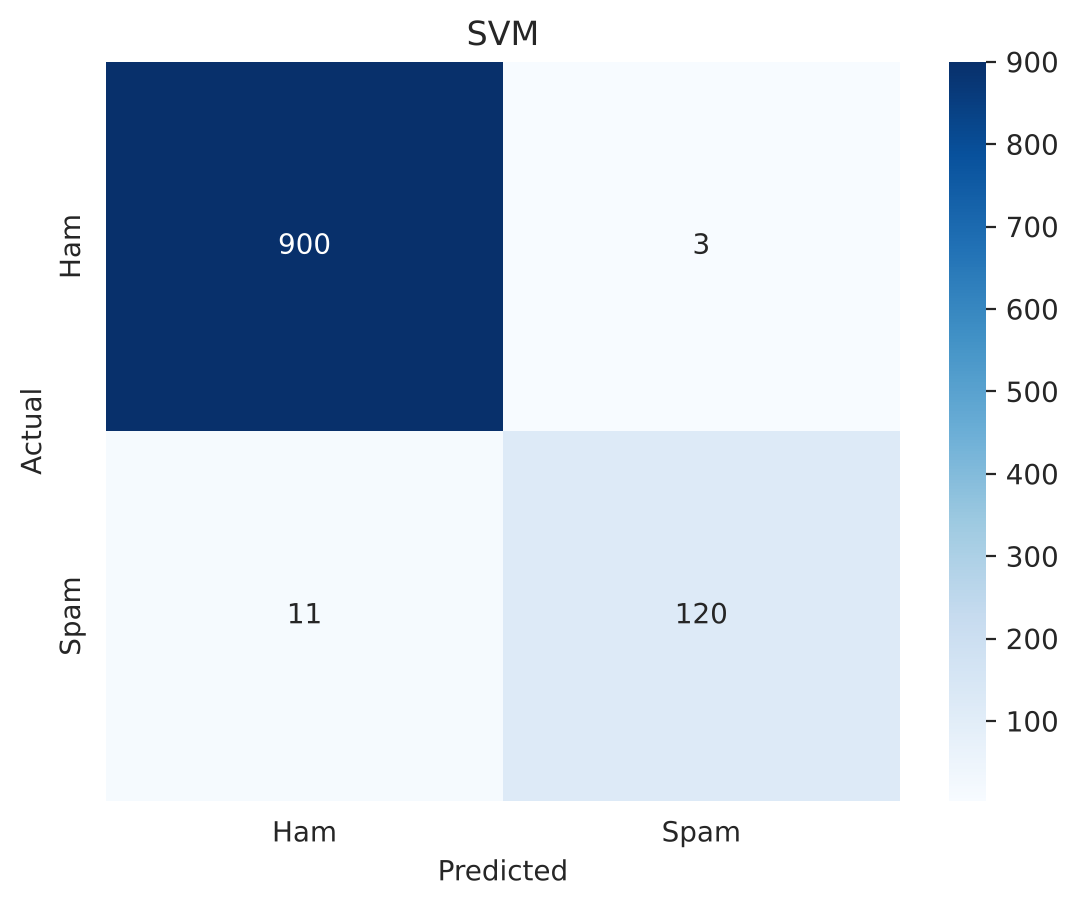

In [6]:
best_name = results_df.loc[results_df['F1'].idxmax(), 'Model']
best_model = models[best_name]
y_pred = best_model.predict(X_test_tfidf)

print('Best model:', best_name, '\n')
print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(best_name)
plt.show()

# TEST ON NEW MESSAGES
New messages must be cleaned with the same `preprocess()` function used in file 1.

In [7]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' url ', text)   # links
    text = re.sub(r'\d+', ' num ', text)                 # numbers
    text = re.sub(r'[^a-z\s]', ' ', text)                # punctuation / symbols
    tokens = text.split()                                 # tokenization
    tokens = [stemmer.stem(w) for w in tokens if w not in stop_words and len(w) > 1]
    return ' '.join(tokens)

In [8]:
def predict_sms(message):
    vec = tfidf.transform([preprocess(message)])
    prob = best_model.predict_proba(vec)[0, 1]
    label = 'Spam' if prob >= 0.5 else 'Not Spam'
    return label, round(prob * 100, 1)

tests = [
    'Congratulations! You have won a free iPhone. Click the link to claim your prize now!',
    'URGENT: your bank account is blocked. Call 09061234567 to verify.',
    'Free entry in a weekly competition. Text WIN to 80086 now',
    'Hey, are we meeting at 6 for dinner today?',
    'Your OTP for login is 483920. Do not share it with anyone.',
    'Can you send me the notes from yesterday class?',
]

for t in tests:
    label, confidence = predict_sms(t)
    print(f'{label:9} ({confidence}% spam)  <-  {t}')

Spam      (91.3% spam)  <-  Congratulations! You have won a free iPhone. Click the link to claim your prize now!
Spam      (83.9% spam)  <-  URGENT: your bank account is blocked. Call 09061234567 to verify.
Spam      (86.9% spam)  <-  Free entry in a weekly competition. Text WIN to 80086 now
Not Spam  (0.4% spam)  <-  Hey, are we meeting at 6 for dinner today?
Not Spam  (8.9% spam)  <-  Your OTP for login is 483920. Do not share it with anyone.
Not Spam  (0.5% spam)  <-  Can you send me the notes from yesterday class?


# SAVE THE MODEL

In [9]:
joblib.dump(best_model, '../model/spam_model.pkl')
joblib.dump(tfidf, '../model/tfidf_vectorizer.pkl')

# In Colab, download the files before the session closes:
# from google.colab import files
# files.download('../model/spam_model.pkl')
# files.download('../model/tfidf_vectorizer.pkl')

['../model/tfidf_vectorizer.pkl']